# 03_read_recordings

Read saved EEG recording sessions, split each session into per-block segments (rest / 1-back / 3-back), and build a combined dataset. The session name is kept as the first field of every record so segments from different sessions never get mixed up.

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110


## 1. Locate saved sessions

Sessions are stored as `session_<n>/` folders (possibly nested under a subject folder), each containing `meta.json`, `signal.npy`, `time.npy`, and `state_changes.csv`.

In [2]:
DATA_ROOT = Path("data")

session_dirs = sorted({p for p in DATA_ROOT.rglob("session_*") if p.is_dir()})
print(f"Found {len(session_dirs)} session(s):")
for d in session_dirs:
    print(" ", d)


Found 1 session(s):
  data/session_1


## 2. Load one session

`session_name` is taken from `meta.json` (`session_id`) and falls back to the folder name. It is stored first so it stays the leading column in every downstream table.

In [3]:
def load_session(session_dir: Path) -> dict:
    meta = json.loads((session_dir / "meta.json").read_text())
    signal = np.load(session_dir / "signal.npy")
    time = np.load(session_dir / "time.npy")

    raw = np.loadtxt(session_dir / "state_changes.csv", delimiter=",", skiprows=1, dtype=str)
    if raw.ndim == 1:
        raw = raw.reshape(1, -1)

    sfreq = float(meta.get("sfreq", 250.0))
    session_name = str(meta.get("session_id", session_dir.name))

    return {
        "session_name": session_name,          # kept first on purpose
        "session_dir": session_dir,
        "meta": meta,
        "subject_id": meta.get("subject_id"),
        "sfreq": sfreq,
        "electrodes": meta.get("electrodes", []),
        "signal": signal,
        "time": time,
        "changes": raw,
    }

sessions = [load_session(d) for d in session_dirs]
for s in sessions:
    print(s["session_name"], s["signal"].shape, s["time"].shape, len(s["changes"]), "state changes")


demo_1 (3990, 8) (3990,) 3 state changes


## 3. Split a session into per-block segments

`state_changes.csv` lists the stream time at which each active label starts. A segment runs from one change to the next (or to the end of the recording). Samples collected while the state was `None` (cut out) are not present in `signal.npy`, so every remaining sample belongs to exactly one segment.

In [4]:
def split_session(session: dict) -> list[dict]:
    segments = []
    changes = session["changes"]
    time = session["time"]
    signal = session["signal"]

    for i, (t_start, label) in enumerate(changes):
        start = float(t_start)
        if i + 1 < len(changes):
            end = float(changes[i + 1, 0])
        else:
            end = float(time[-1]) + 1.0 / session["sfreq"]

        mask = (time >= start) & (time < end)
        segment_idx = i

        segments.append({
            "session_name": session["session_name"],   # first field on purpose
            "subject_id": session["subject_id"],
            "label": str(label),
            "segment_idx": segment_idx,
            "start_time": start,
            "end_time": end,
            "duration_s": end - start,
            "n_samples": int(mask.sum()),
            "sfreq": session["sfreq"],
            "electrodes": session["electrodes"],
            "signal": signal[mask],
            "time": time[mask],
        })
    return segments

all_segments = []
for session in sessions:
    all_segments.extend(split_session(session))

print(f"Total segments: {len(all_segments)}")
for seg in all_segments:
    print(f"  {seg['session_name']:>12s} | {seg['label']:>5s} | {seg['n_samples']:5d} samples | {seg['duration_s']:5.2f} s")


Total segments: 3
        demo_1 | 3back |   750 samples | 10.96 s
        demo_1 |  rest |  1740 samples |  9.64 s
        demo_1 |  rest |  1500 samples |  6.00 s


## 4. Combined table

Build a pandas DataFrame with `session_name` as the first column. Array columns are kept as objects so the table stays readable; the underlying arrays are in `all_segments`.

In [5]:
records = []
for seg in all_segments:
    records.append({
        "session_name": seg["session_name"],
        "subject_id": seg["subject_id"],
        "label": seg["label"],
        "segment_idx": seg["segment_idx"],
        "start_time": seg["start_time"],
        "end_time": seg["end_time"],
        "duration_s": seg["duration_s"],
        "n_samples": seg["n_samples"],
        "sfreq": seg["sfreq"],
    })

df = pd.DataFrame(records, columns=[
    "session_name", "subject_id", "label", "segment_idx",
    "start_time", "end_time", "duration_s", "n_samples", "sfreq",
])
df


,session_name,subject_id,label,segment_idx,start_time,end_time,duration_s,n_samples,sfreq
0,demo_1,demo,3back,0,2.08,13.04,10.96,750,250.0
1,demo_1,demo,rest,1,13.04,22.68,9.64,1740,250.0
2,demo_1,demo,rest,2,22.68,28.68,6.00,1500,250.0


## 5. Quick look at one segment

Plot the first channel of the first segment of the first session with the block boundaries marked.

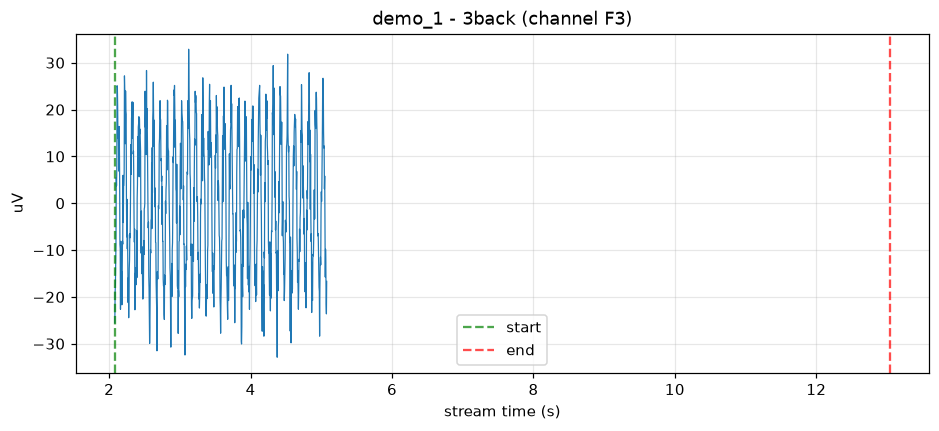

In [6]:
if all_segments:
    seg = all_segments[0]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(seg["time"], seg["signal"][:, 0], lw=0.8)
    ax.axvline(seg["start_time"], color="g", linestyle="--", alpha=0.7, label="start")
    ax.axvline(seg["end_time"], color="r", linestyle="--", alpha=0.7, label="end")
    ax.set_title(f"{seg['session_name']} - {seg['label']} (channel {seg['electrodes'][0]})")
    ax.set_xlabel("stream time (s)")
    ax.set_ylabel("uV")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()


## 6. Save the split segments

Each segment is saved as a `.npy` file whose name starts with the session name, followed by the label and segment index. A manifest CSV (also session-name-first) records the metadata for every segment.

In [ ]:
def safe(name: str) -> str:
    return re.sub(r"[^A-Za-z0-9._-]+", "_", name).strip("_")

OUT_DIR = Path("splits")
OUT_DIR.mkdir(exist_ok=True)

manifest_rows = []
for seg in all_segments:
    fname = f"{safe(seg['session_name'])}__{safe(seg['label'])}__{seg['segment_idx']}.npy"
    fpath = OUT_DIR / fname
    np.save(fpath, seg["signal"])
    manifest_rows.append({
        "session_name": seg["session_name"],
        "subject_id": seg["subject_id"],
        "label": seg["label"],
        "segment_idx": seg["segment_idx"],
        "start_time": seg["start_time"],
        "end_time": seg["end_time"],
        "duration_s": seg["duration_s"],
        "n_samples": seg["n_samples"],
        "sfreq": seg["sfreq"],
        "file": fname,
    })

manifest = pd.DataFrame(manifest_rows, columns=[
    "session_name", "subject_id", "label", "segment_idx",
    "start_time", "end_time", "duration_s", "n_samples", "sfreq", "file",
])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
print(f"Saved {len(manifest_rows)} segment files to {OUT_DIR.resolve()}")
manifest


### Takeaways

- `session_name` is the first field of every segment record and the first column of every table, so sessions stay distinguishable after splitting.
- Segments are sliced directly from the saved `signal.npy`/`time.npy` using `state_changes.csv`, so no re-recording is needed.
- The `splits/` folder plus `manifest.csv` can be fed straight into the preprocessing / classification notebooks.